In [1]:
from tensorflow.keras.models import Sequential 

In [2]:
import numpy as np

In [3]:
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Dense,Flatten


In [4]:
X_train = np.loadtxt(r"input.csv",delimiter=',')
Y_train = np.loadtxt(r"labels.csv",delimiter=',')

X_test = np.loadtxt(r"input_test.csv",delimiter=',')
Y_test = np.loadtxt(r"labels_test.csv",delimiter=',')

In [5]:
X_train = X_train.reshape(len(X_train), 100, 100, 3)
Y_train = Y_train.reshape(len(Y_train), 1)

X_test = X_test.reshape(len(X_test), 100, 100, 3)
Y_test = Y_test.reshape(len(Y_test), 1)

X_train = X_train / 255.0
X_test = X_test / 255.0

In [6]:
print("Shape of X_train",X_train.shape)
print("Shape of Y_train",Y_train.shape)

Shape of X_train (2000, 100, 100, 3)
Shape of Y_train (2000, 1)


In [7]:
print("Shape of X_test",X_test.shape)
print("Shape of Y_test",Y_test.shape)

Shape of X_test (400, 100, 100, 3)
Shape of Y_test (400, 1)


In [8]:
X_train[1,:]

array([[[0.51372549, 0.50196078, 0.52941176],
        [0.62745098, 0.61568627, 0.64313725],
        [0.77647059, 0.75294118, 0.8       ],
        ...,
        [0.98039216, 0.97647059, 0.96862745],
        [1.        , 1.        , 0.99215686],
        [0.98039216, 0.97647059, 0.96078431]],

       [[0.54901961, 0.5372549 , 0.56470588],
        [0.49803922, 0.48627451, 0.51372549],
        [0.47058824, 0.44705882, 0.48627451],
        ...,
        [0.98431373, 0.99215686, 0.98823529],
        [0.99607843, 1.        , 0.99215686],
        [0.99607843, 1.        , 0.98431373]],

       [[0.8       , 0.79215686, 0.81176471],
        [0.73333333, 0.7254902 , 0.74509804],
        [0.57647059, 0.55686275, 0.58039216],
        ...,
        [0.97647059, 1.        , 1.        ],
        [0.93333333, 0.96862745, 0.94901961],
        [0.90980392, 0.94509804, 0.9254902 ]],

       ...,

       [[0.68235294, 0.71372549, 0.76470588],
        [0.6745098 , 0.70588235, 0.75686275],
        [0.69803922, 0

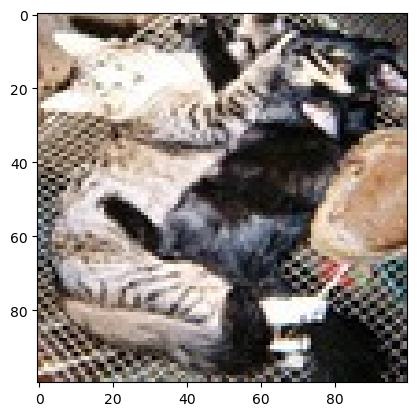

In [9]:
import matplotlib.pyplot as plt
import random
idx = random.randint(0,len(X_train))
plt.imshow(X_train[idx,:])
plt.show()

In [10]:
model = Sequential()

model.add(Conv2D(32, (3,3), activation = 'relu', input_shape = (100, 100, 3)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(32, (3,3), activation = 'relu'))
model.add(MaxPooling2D((2,2)))

model.add(Flatten())
model.add(Dense(64, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

C:\Users\DELL\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [12]:
model.fit(X_train, Y_train, epochs = 5, batch_size = 64)

Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 120ms/step - accuracy: 0.5430 - loss: 0.7101
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 119ms/step - accuracy: 0.6645 - loss: 0.6196
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 120ms/step - accuracy: 0.7340 - loss: 0.5331
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 120ms/step - accuracy: 0.7830 - loss: 0.4594
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 119ms/step - accuracy: 0.8245 - loss: 0.3938


In [13]:
model.evaluate(X_test, Y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6725 - loss: 0.6574


[0.6573799848556519, 0.6725000143051147]

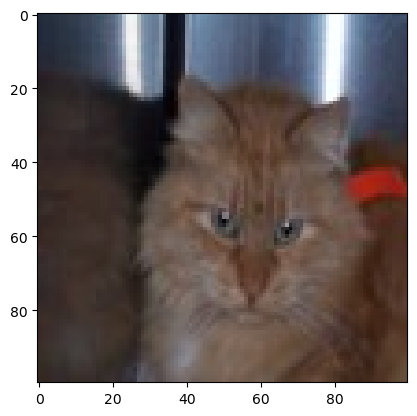

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step
Our model says it is a : Cat


In [14]:
idx2 = random.randint(0,len(Y_test))
plt.imshow(X_test[idx2,:])
plt.show()

y_pred = model.predict(X_test[idx2,:].reshape(1, 100, 100, 3))
y_pred = y_pred > 0.5
if(y_pred == 0):
    pred ="Dog"
else:
    pred="Cat"
print("Our model says it is a :", pred)